# Explaining payment difficulty with logical models

**Explainable Artificial Intelligence (IAX), MUIA, Universidad Politécnica de Madrid, 2026/27**
Hands on project, Unit 2. Phase I (preliminary submission)

| Name | Email |
|:--|:--|
| Iker Rosales Saiz | iker.rosales@alumnos.upm.es |
| Pratham Jaikishan Bakshani Karamchandani | |
| Hugo Aguilar Sanchez | |

In this project we want to predict whether a credit card client will have payment difficulties next month (`payment_difficulty_next_month`) and, more importantly, understand what the models actually learn. For this first submission we only work with logical models. We train a decision tree, a rule list and a rule set, compare them with 5 fold cross validation and keep the one that gives the best balance between accuracy and interpretability. Logistic regression and the EBM will come in Phase II.

## 0. Setup

Besides the usual stack we need `imodels` (Bayesian rule list), `wittgenstein` (RIPPER) and `gosdt`. As in the class notebook, `gosdt` is pinned to 0.1.8 because newer releases changed the API.

In [1]:
import importlib.metadata
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REQUIRED = {"imodels": None, "wittgenstein": None, "gosdt": "0.1.8"}


def installed_version(pkg):
    try:
        return importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:
        return None


missing = [f"{p}=={v}" if v else p for p, v in REQUIRED.items()
           if installed_version(p) is None or (v and installed_version(p) != v)]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

In [2]:
import contextlib
import io
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import imodels
import wittgenstein as lw
from gosdt import GOSDT
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, _tree, plot_tree

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEED = 42
TARGET = "payment_difficulty_next_month"

# two colours for the two classes, gray for reference lines
C_NEG, C_POS, C_REF = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
})

In [3]:
DATA_DIR = Path(".")
if IN_COLAB and not (DATA_DIR / "train.csv").exists():
    from google.colab import files
    files.upload()  # upload train.csv and test.csv

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, " test:", test.shape)
train.head()

train: (25000, 17)  test: (5000, 16)


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,payment_difficulty_next_month
0,CR26-120473,80000,male,university,married,54,0,0,0,24600,3700,10300,0.07,0,0.33,no,0
1,CR26-127004,20000,male,university,single,30,0,0,0,21100,21000,6700,0.05,0,1.98,no,0
2,CR26-116408,230000,female,graduate_school,married,35,0,0,0,1700,3600,5100,0.49,1,0.03,no,0
3,CR26-125768,150000,female,university,married,51,0,0,0,76100,-8800,15400,0.03,0,0.48,no,0
4,CR26-118040,500000,male,graduate_school,married,43,0,0,0,121600,26200,25000,0.03,0,0.25,yes,0


## 1. Quick look at the data

Basic checks first: types, missing values, duplicates and how balanced the target is.

In [ ]:
CAT_COLS = ["sex", "education", "marital_status", "repayment_assistance_plan"]
NUM_COLS = [c for c in train.columns if c not in CAT_COLS + ["row_id", TARGET]]

print("missing values(train / test):", train.isna().sum().sum(),"/",test.isna().sum().sum())
print("row_id unique:", train.row_id.is_unique, "| overlap with test:", len(set(train.row_id) & set(test.row_id)))
print("duplicated rows ignoring row_id:", train.drop(columns="row_id").duplicated().sum())
print(f"positive rate: {train[TARGET].mean():.3f}  ->  majority class baseline accuracy = {1 - train[TARGET].mean():.3f}")
train[NUM_COLS].describe().T.round(2)

missing values (train / test): 0 / 0
row_id unique: True | overlap with test: 0
duplicated rows ignoring row_id: 18
positive rate: 0.212  ->  majority class baseline accuracy = 0.788


,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0


No missing values and no overlap between train and test ids. There are 18 duplicated rows if we ignore `row_id`, but with 25k clients and rounded amounts they can easily be different people with the same profile, so we keep them.

The target is imbalanced (21.2% positives), so the number to beat is **78.8% accuracy**. A few ranges are worth noting: `average_bill_6m` can be negative (credit in favour of the client), the money variables have very long tails (payments up to 2.3M) and `payment_to_bill_ratio_6m` and `utilization_sep` are capped at 5 and 2 by construction. For trees none of this is a big deal because they only look at thresholds, so we don't transform anything.

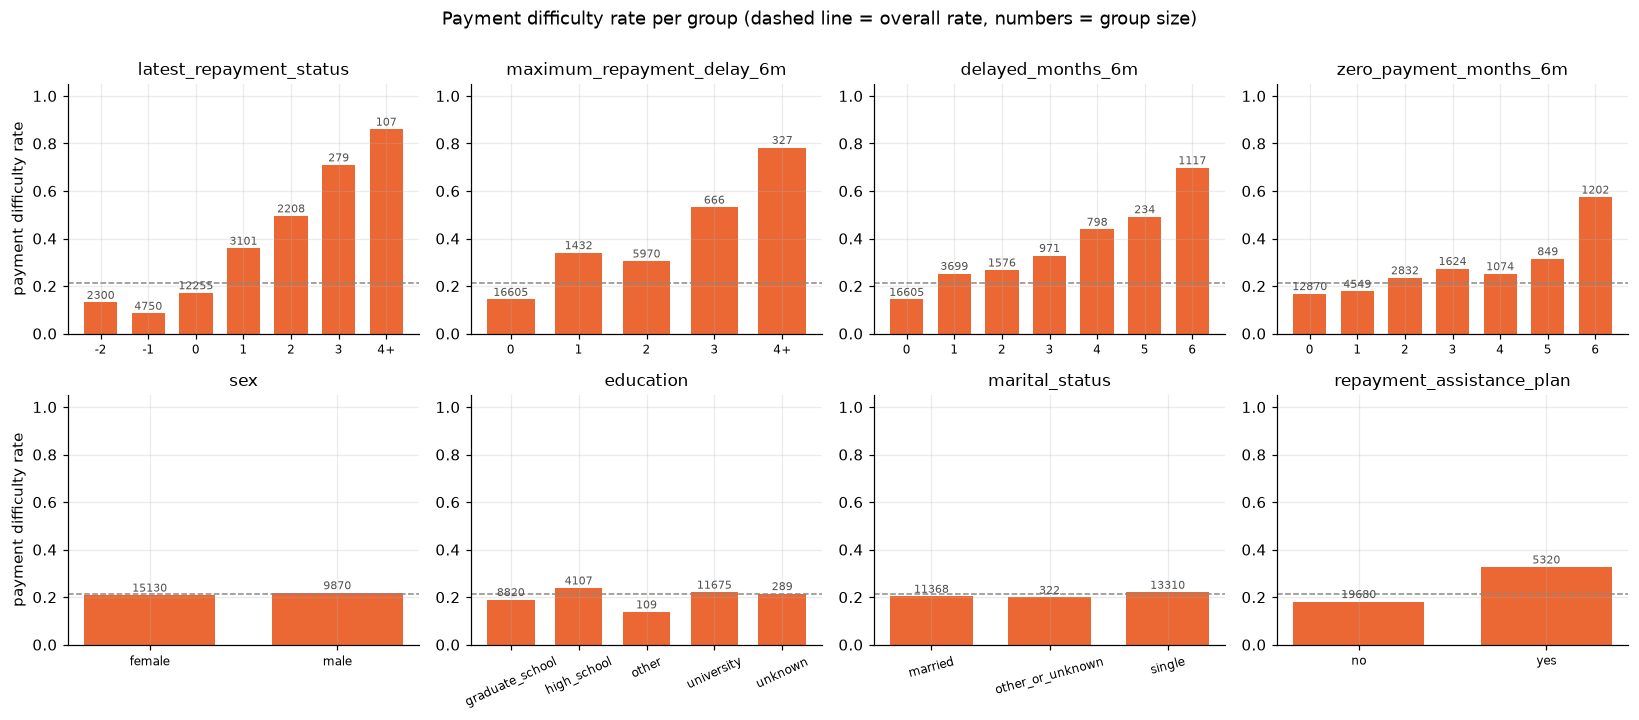

In [5]:
def rate_plot(ax, s, y, title, order=None):
    """Positive rate per group, with the group size written on each bar."""
    g = y.groupby(s).agg(["mean", "size"])
    if order is not None:
        g = g.reindex(order)
    ax.bar(g.index.astype(str), g["mean"], color=C_POS, width=0.7)
    ax.axhline(y.mean(), color=C_REF, ls="--", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m + 0.015, f"{n}", ha="center", fontsize=7, color="#52514e")
    ax.set_title(title)
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", labelsize=8)


y_all = train[TARGET]
cap4 = lambda s: s.clip(upper=4).astype(str).replace("4", "4+")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
rate_plot(axes[0, 0], cap4(train.latest_repayment_status), y_all, "latest_repayment_status",
          order=["-2", "-1", "0", "1", "2", "3", "4+"])
rate_plot(axes[0, 1], cap4(train.maximum_repayment_delay_6m), y_all, "maximum_repayment_delay_6m",
          order=["0", "1", "2", "3", "4+"])
rate_plot(axes[0, 2], train.delayed_months_6m, y_all, "delayed_months_6m")
rate_plot(axes[0, 3], train.zero_payment_months_6m, y_all, "zero_payment_months_6m")
for ax, c in zip(axes[1], CAT_COLS):
    rate_plot(ax, train[c], y_all, c)
axes[1, 1].tick_params(axis="x", rotation=25)
axes[1, 2].tick_params(axis="x", rotation=15)
for ax in axes[:, 0]:
    ax.set_ylabel("payment difficulty rate")
fig.suptitle("Payment difficulty rate per group (dashed line = overall rate, numbers = group size)", y=1.0)
plt.tight_layout()
plt.show()

The signal is clearly in the repayment behaviour. The difficulty rate grows almost monotonically with the delay variables, from around 15% with no delays up to 70% or more for clients delayed in all 6 months or with a maximum delay of 4+ months.

`latest_repayment_status` is the exception: the undocumented codes -2, -1 and 0 are not ordered (-1 has the lowest rate, 8.5%) and the real jump is between 0 and 1, when there is an actual delay. For `zero_payment_months_6m` the rate barely moves until 6, where it jumps to 57%, so "paid nothing in six months" is a very different situation from "skipped a couple of payments".

The demographic variables are almost flat. Sex in particular gives 20.8% vs 21.8%, so we don't expect the models to use it (we will still audit the errors by sex in Phase II). The assistance plan shows a higher rate (32.7% vs 18.1%), but the plan is offered to clients who are already struggling, so this is selection and not an effect of the plan.

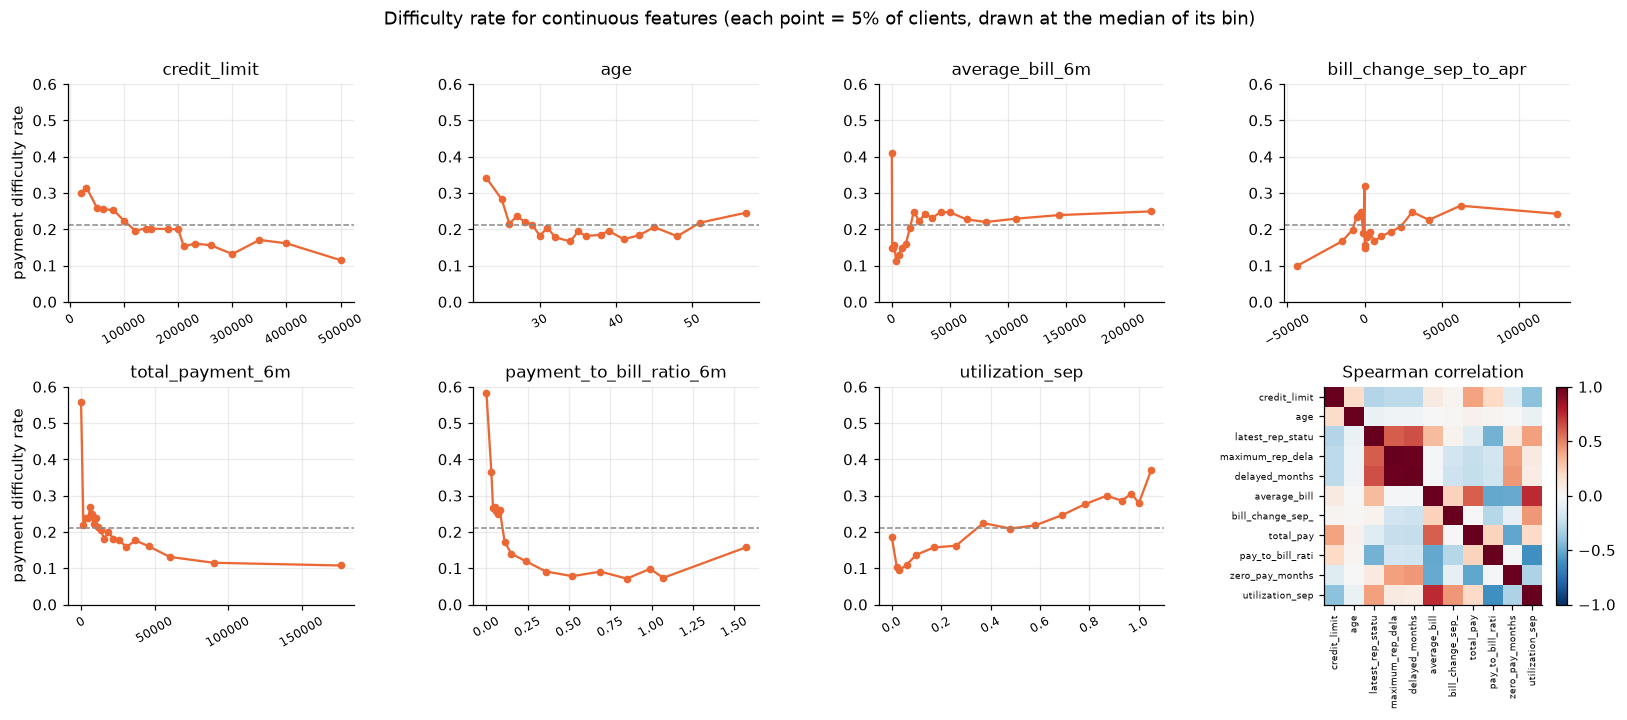

In [6]:
CONT_COLS = ["credit_limit", "age", "average_bill_6m", "bill_change_sep_to_apr",
             "total_payment_6m", "payment_to_bill_ratio_6m", "utilization_sep"]


fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.flat, CONT_COLS):
    # 20 quantile bins (5% of clients each), each point drawn at the median value of its bin
    bins = pd.qcut(train[c], q=20, duplicates="drop")
    g = (pd.DataFrame({"x": train[c], "y": y_all}).groupby(bins, observed=True)
         .agg(x=("x", "median"), rate=("y", "mean")))
    ax.plot(g.x, g.rate, marker="o", ms=4, lw=1.5, color=C_POS)
    ax.axhline(y_all.mean(), color=C_REF, ls="--", lw=1)
    ax.ticklabel_format(axis="x", style="plain")
    ax.tick_params(axis="x", labelsize=8, rotation=30)
    ax.set_title(c)
    ax.set_ylim(0, 0.6)
axes[0, 0].set_ylabel("payment difficulty rate")
axes[1, 0].set_ylabel("payment difficulty rate")

# redundancy between the numeric features
corr = train[NUM_COLS].corr(method="spearman")
ax = axes[1, 3]
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_COLS)))
ax.set_yticks(range(len(NUM_COLS)))
short = [c.replace("_6m", "").replace("repayment", "rep").replace("payment", "pay")[:16] for c in NUM_COLS]
ax.set_xticklabels(short, rotation=90, fontsize=6)
ax.set_yticklabels(short, fontsize=6)
ax.grid(False)
ax.set_title("Spearman correlation")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Difficulty rate for continuous features (each point = 5% of clients, drawn at the median of its bin)", y=1.0)
plt.tight_layout()
plt.show()

For the continuous features the effects are weaker and not always monotonic:

* `payment_to_bill_ratio_6m` is the clearest one. Clients who paid nothing (ratio 0) have a 58% difficulty rate, it stays around 26% up to 0.08 and drops below 10% from ~0.35 on.
* Exact zeros stand out in general: `total_payment_6m = 0` gives 56%, `average_bill_6m = 0` gives 41% and `bill_change_sep_to_apr = 0` gives 32%. These are probably inactive accounts or clients that simply stopped paying, and a tree can isolate them with a single threshold.
* `utilization_sep` goes up steadily (from ~10% to 37% when the card is over the limit), while `credit_limit` and `total_payment_6m` go down. Young clients are also riskier (34% at 23 years old).

The correlation matrix shows strong redundancy between the three delay variables and between bill, utilization and payment ratio. So we shouldn't read too much into which of them a tree picks: swapping one for a correlated one would probably give a similar tree.

## 2. Preprocessing and evaluation setup

**Encoding.** Trees and RIPPER do not care about scale, so the numeric features go in raw. The four categorical ones are one hot encoded. `latest_repayment_status` is kept as a number: its negative codes are not documented, but a tree can still isolate them with thresholds, so we don't need to invent a meaning for them.

**Binary features.** GOSDT and the Bayesian rule list need binary inputs. Following the GOSDT class notebook, instead of one hot encoding every value we build a small set of `feature >= threshold` indicators (named `feature_ge_threshold`). The thresholds come from the plots above (where the difficulty rate jumps) plus some round numbers, and we keep them coarse so the search stays cheap. `depth_budget` in GOSDT counts the leaf level too, so `depth_budget=3` means at most two levels of splits. We tried `depth_budget=5` too, but every fit hits the 60 s time limit without finding a better tree, so we left it out.

**Evaluation.** Everything (hyperparameters, model comparison, threshold) is decided with the same stratified 5 fold split of `train.csv`. We report accuracy because it is what `test.csv` will be graded on, but with 21% positives accuracy alone is misleading (predicting "no" for everyone already gets 0.788), so we also track ROC AUC, balanced accuracy and F1 of the positive class. For interpretability we count leaves or rules.

In [7]:
X = pd.get_dummies(train.drop(columns=["row_id", TARGET]), columns=CAT_COLS, dtype=int)
y = train[TARGET]
X_test = pd.get_dummies(test.drop(columns=["row_id"]), columns=CAT_COLS, dtype=int).reindex(columns=X.columns, fill_value=0)

THRESHOLDS = {
    "latest_repayment_status": [0, 1, 2],
    "maximum_repayment_delay_6m": [1, 2, 3],
    "delayed_months_6m": [1, 3, 6],
    "zero_payment_months_6m": [1, 3, 6],
    "payment_to_bill_ratio_6m": [0.03, 0.1, 0.5],
    "total_payment_6m": [2500, 10000],
    "utilization_sep": [0.5, 0.9],
    "credit_limit": [50000, 150000],
    "age": [25, 45],
    "bill_change_sep_to_apr": [0],
}


def make_binary_features(df):
    cols = {f"{f}_ge_{t}": (df[f] >= t).astype(int) for f, ts in THRESHOLDS.items() for t in ts}
    cols["assistance_plan"] = df["repayment_assistance_plan_yes"]
    return pd.DataFrame(cols, index=df.index)


X_bin = make_binary_features(X)
X_test_bin = make_binary_features(X_test)
print("one hot features:", X.shape[1], "| binary features:", X_bin.shape[1])
X_bin.mean().round(3).to_frame("prevalence").T

one hot features: 23 | binary features: 25


,latest_repayment_status_ge_0,latest_repayment_status_ge_1,latest_repayment_status_ge_2,maximum_repayment_delay_6m_ge_1,maximum_repayment_delay_6m_ge_2,maximum_repayment_delay_6m_ge_3,delayed_months_6m_ge_1,delayed_months_6m_ge_3,delayed_months_6m_ge_6,zero_payment_months_6m_ge_1,zero_payment_months_6m_ge_3,zero_payment_months_6m_ge_6,payment_to_bill_ratio_6m_ge_0.03,payment_to_bill_ratio_6m_ge_0.1,payment_to_bill_ratio_6m_ge_0.5,total_payment_6m_ge_2500,total_payment_6m_ge_10000,utilization_sep_ge_0.5,utilization_sep_ge_0.9,credit_limit_ge_50000,credit_limit_ge_150000,age_ge_25,age_ge_45,bill_change_sep_to_apr_ge_0,assistance_plan
prevalence,0.718,0.228,0.104,0.336,0.279,0.04,0.336,0.125,0.045,0.485,0.19,0.048,0.938,0.489,0.283,0.899,0.622,0.412,0.205,0.856,0.491,0.91,0.177,0.625,0.213


In [8]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def cv_evaluate(make_model, X, y, name=None):
    """5 fold CV with the shared split. Returns mean/std of the metrics plus out of fold probabilities."""
    rows, oof = [], np.zeros(len(y))
    for tr, va in CV.split(X, y):
        model = make_model()
        t0 = time.time()
        model.fit(X.iloc[tr], y.iloc[tr])
        fit_time = time.time() - t0
        proba = np.asarray(model.predict_proba(X.iloc[va]))[:, 1]
        pred = np.asarray(model.predict(X.iloc[va])).astype(int)
        oof[va] = proba
        rows.append({"accuracy": accuracy_score(y.iloc[va], pred),
                     "roc_auc": roc_auc_score(y.iloc[va], proba),
                     "balanced_acc": balanced_accuracy_score(y.iloc[va], pred),
                     "f1": f1_score(y.iloc[va], pred),
                     "fit_s": fit_time,
                     "size": model.n_leaves() if hasattr(model, "n_leaves") else np.nan})
    res = pd.DataFrame(rows)
    summary = pd.concat([res.mean().add_suffix("_mean"), res.std().add_suffix("_std")])
    summary.name = name
    return summary, oof


def show_cv(summary):
    keys = ["accuracy", "roc_auc", "balanced_acc", "f1"]
    return pd.DataFrame({k: [f"{summary[k + '_mean']:.4f} ± {summary[k + '_std']:.4f}"] for k in keys}
                        | {"fit (s)": [f"{summary['fit_s_mean']:.1f}"]}, index=[summary.name])


results, oof_probs = {}, {}
results["Majority baseline"], _ = cv_evaluate(lambda: DummyClassifier(strategy="most_frequent"), X, y, "Majority baseline")
show_cv(results["Majority baseline"])

,accuracy,roc_auc,balanced_acc,f1,fit (s)
Majority baseline,0.7879 ± 0.0001,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0


## 3. Model 1: decision tree

### 3.1 CART (scikit-learn)

We start with the standard greedy tree. The two knobs that matter most for interpretability are `max_depth` and `min_samples_leaf` (we saw in class how an unrestricted tree just memorises the training data), so we grid search them with the 5 fold CV.

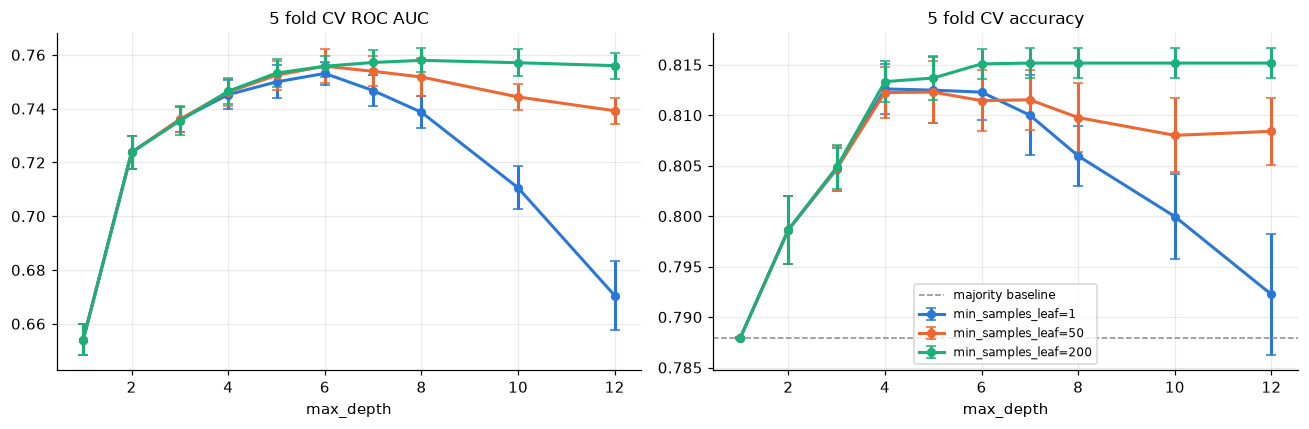

,param_max_depth,param_min_samples_leaf,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy,std_test_accuracy
29,12,200,0.7560,0.0048,0.8152,0.0014
20,7,200,0.7572,0.0045,0.8152,0.0014
23,8,200,0.7580,0.0044,0.8152,0.0014
26,10,200,0.7571,0.0050,0.8152,0.0014
17,6,200,0.7558,0.0039,0.8151,0.0015
14,5,200,0.7532,0.0051,0.8137,0.0022
11,4,200,0.7465,0.0046,0.8133,0.0020
9,4,1,0.7452,0.0053,0.8126,0.0025


In [9]:
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    param_grid={"max_depth": [1, 2, 3, 4, 5, 6, 7, 8, 10, 12], "min_samples_leaf": [1, 50, 200]},
    scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
    refit=False, cv=CV, n_jobs=-1,
)
grid.fit(X, y)
cv_tree = pd.DataFrame(grid.cv_results_)
cv_tree = cv_tree[["param_max_depth", "param_min_samples_leaf", "mean_test_roc_auc", "std_test_roc_auc",
                   "mean_test_accuracy", "std_test_accuracy"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (msl, g), col in zip(cv_tree.groupby("param_min_samples_leaf"), ["#2a78d6", "#eb6834", "#1baf7a"]):
    for ax, m in zip(axes, ["roc_auc", "accuracy"]):
        ax.errorbar(g.param_max_depth, g[f"mean_test_{m}"], yerr=g[f"std_test_{m}"], marker="o", ms=5,
                    lw=2, capsize=3, color=col, label=f"min_samples_leaf={msl}")
axes[1].axhline(1 - y.mean(), color=C_REF, ls="--", lw=1, label="majority baseline")
axes[0].set_title("5 fold CV ROC AUC")
axes[1].set_title("5 fold CV accuracy")
for ax in axes:
    ax.set_xlabel("max_depth")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

cv_tree.sort_values("mean_test_accuracy", ascending=False).head(8).round(4)

With `min_samples_leaf=1` the tree starts overfitting after depth 6 and both metrics drop, the same behaviour we saw with the moons example in class. With `min_samples_leaf=200` the curves just flatten, because leaves can't get any smaller. The key point is that **accuracy is basically flat from depth 4 on** (0.813 to 0.815), so the extra depth buys almost nothing and costs a lot of readability. AUC keeps improving a bit until depth 6 to 8, since deeper trees rank clients better even when the 0.5 decision doesn't change.

To choose a configuration we use the same rule for every model in the notebook: **take the smallest model whose CV accuracy is within 0.002 of the best one in its grid** (0.002 is roughly one standard deviation across folds). Here that means depth 4 instead of depth 7.

In [10]:
# selection rule used for every model: the smallest model within TOL accuracy of the best one in its grid
TOL = 0.002
best = cv_tree.loc[cv_tree.mean_test_accuracy.idxmax()]
candidates = cv_tree[cv_tree.mean_test_accuracy >= best.mean_test_accuracy - TOL]
chosen = candidates.sort_values(["param_max_depth", "param_min_samples_leaf"], ascending=[True, False]).iloc[0]
TREE_PARAMS = {"max_depth": int(chosen.param_max_depth), "min_samples_leaf": int(chosen.param_min_samples_leaf)}
print(f"best accuracy {best.mean_test_accuracy:.4f} (max_depth={best.param_max_depth}, min_samples_leaf={best.param_min_samples_leaf})")
print("chosen:", TREE_PARAMS)

results["CART"], oof_probs["CART"] = cv_evaluate(
    lambda: DecisionTreeClassifier(**TREE_PARAMS, random_state=SEED), X, y, "CART")
cart = DecisionTreeClassifier(**TREE_PARAMS, random_state=SEED).fit(X, y)
print("leaves:", cart.get_n_leaves())
show_cv(results["CART"])

best accuracy 0.8152 (max_depth=7.0, min_samples_leaf=200.0)
chosen: {'max_depth': 4, 'min_samples_leaf': 200}


leaves: 14


,accuracy,roc_auc,balanced_acc,f1,fit (s)
CART,0.8133 ± 0.0023,0.7465 ± 0.0051,0.6024 ± 0.0045,0.3491 ± 0.0107,0.1


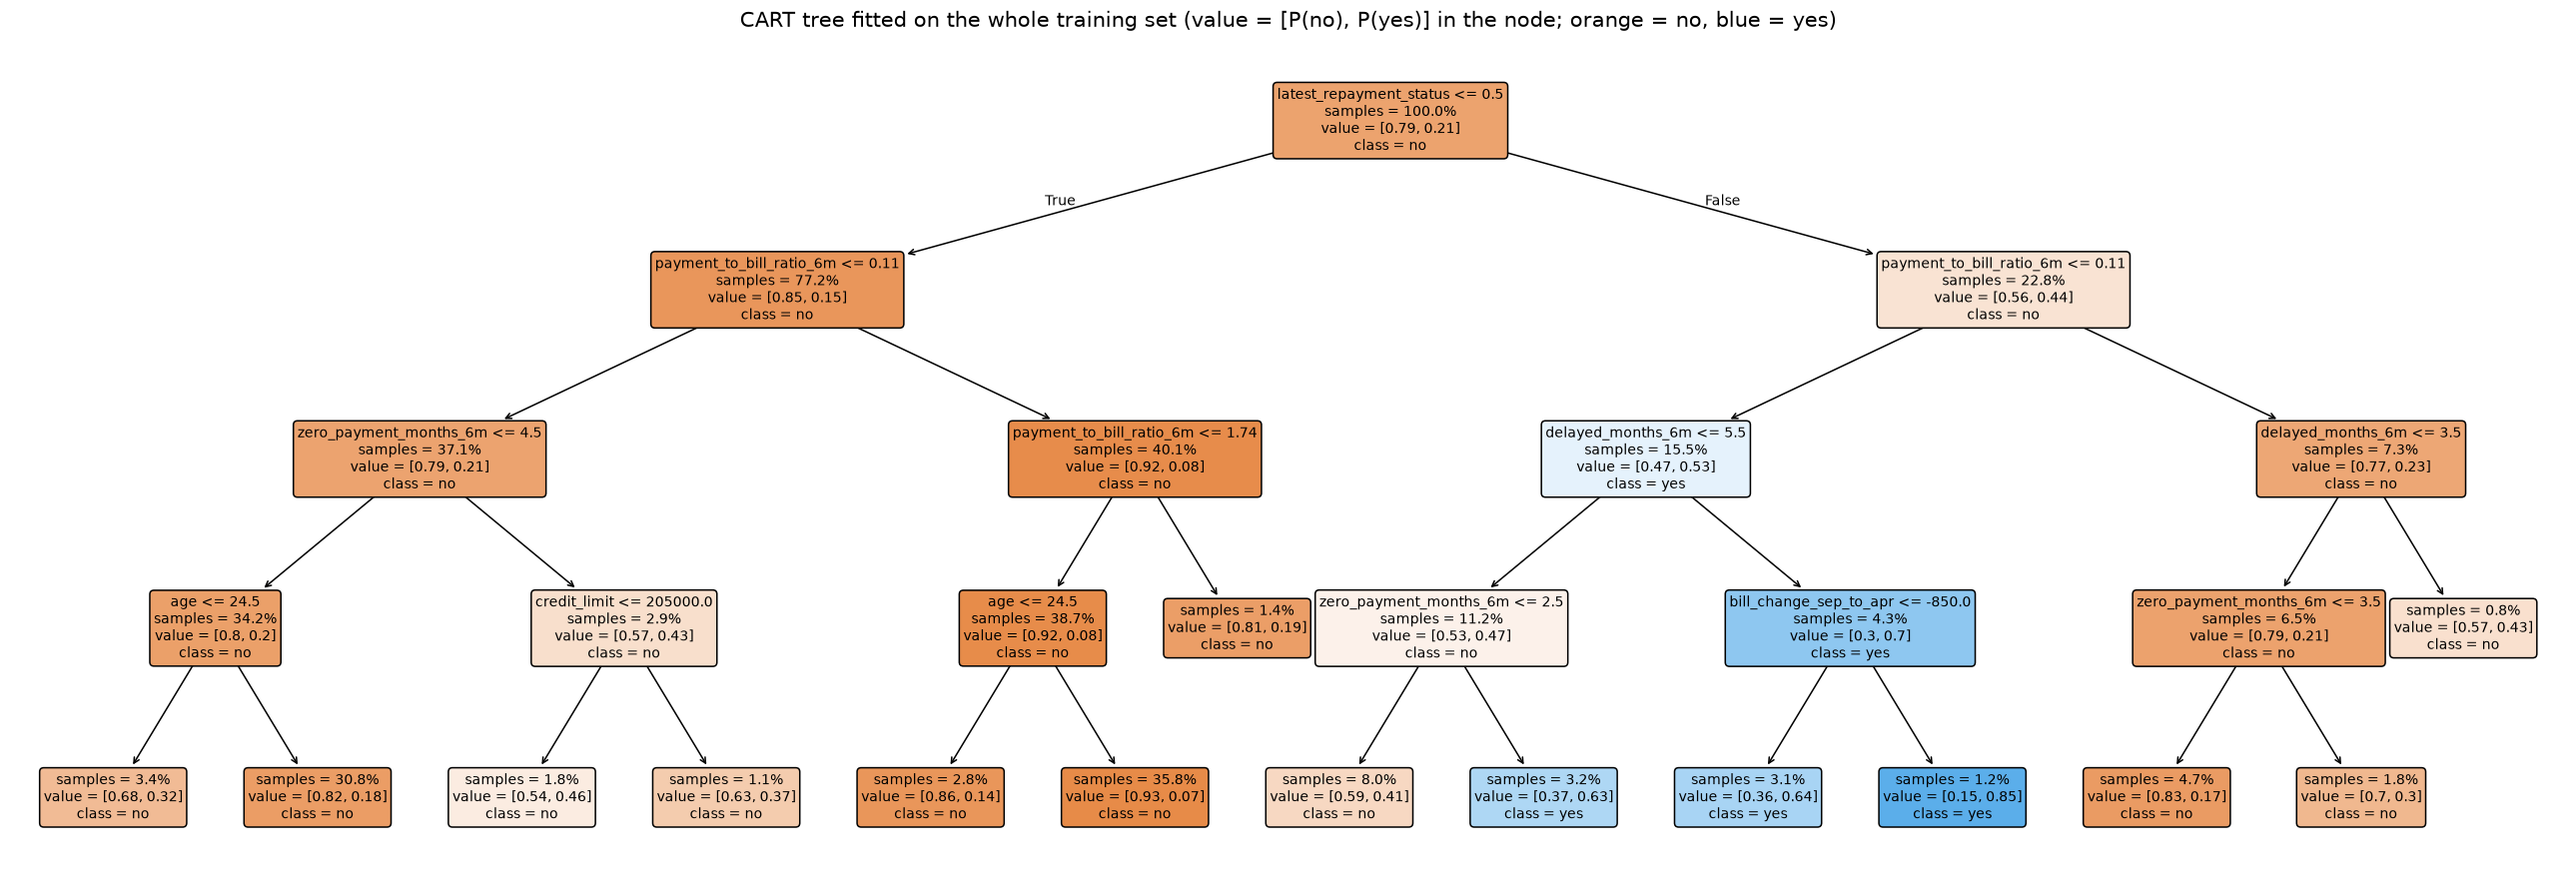

In [11]:
fig = plt.figure(figsize=(30, 10))
plot_tree(cart, feature_names=list(X.columns), class_names=["no", "yes"], filled=True,
          impurity=False, proportion=True, rounded=True, fontsize=9, precision=2)
plt.title("CART tree fitted on the whole training set (value = [P(no), P(yes)] in the node; orange = no, blue = yes)", fontsize=14)
plt.show()

How to read it: the root asks `latest_repayment_status > 0.5`, i.e. whether the client is currently late. This groups the codes -2, -1 and 0 together, which is convenient because we don't need to interpret them. In both branches the second question is the same: did the client pay more than ~11% of the bills in the last 6 months?

Only 3 of the 14 leaves predict "yes", and all of them are on the "currently late and paying little" side:

* late, low payment ratio and 3+ months without paying anything (63%)
* late, low payment ratio and delayed all 6 months (64% or 85% depending on the bill change)

Everything else predicts "no", even leaves with 40 to 46% difficulty. That explains the low recall: with 21% positives the tree only says "yes" when it's quite sure. Also, several splits don't change the prediction at all (both children say "no", e.g. `age <= 24.5` or `credit_limit <= 205000`). They only refine the probabilities, so for classification the tree could be pruned to far fewer leaves with exactly the same predictions.

In [12]:
def get_rules(tree, feature_names, class_names):
    """Tree -> list of if/then rules sorted by support (adapted from the class notebook)."""
    t = tree.tree_
    names = [feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined" for i in t.feature]
    paths = []

    def recurse(node, path):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            thr = np.round(t.threshold[node], 3)
            recurse(t.children_left[node], path + [f"({names[node]} <= {thr})"])
            recurse(t.children_right[node], path + [f"({names[node]} > {thr})"])
        else:
            paths.append((path, t.value[node][0], t.n_node_samples[node]))

    recurse(0, [])
    paths.sort(key=lambda p: -p[2])
    rules = []
    for conds, value, n in paths:
        k = int(np.argmax(value))
        rules.append(f"if {' and '.join(conds)} then {class_names[k]} "
                     f"(p_yes = {value[1] / value.sum():.2f}) | {n:,} samples")
    return rules


for r in get_rules(cart, list(X.columns), ["no", "yes"]):
    print(r)

if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m > 0.105) and (payment_to_bill_ratio_6m <= 1.735) and (age > 24.5) then no (p_yes = 0.07) | 8,953 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (zero_payment_months_6m <= 4.5) and (age > 24.5) then no (p_yes = 0.18) | 7,698 samples
if (latest_repayment_status > 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (delayed_months_6m <= 5.5) and (zero_payment_months_6m <= 2.5) then no (p_yes = 0.41) | 2,007 samples
if (latest_repayment_status > 0.5) and (payment_to_bill_ratio_6m > 0.105) and (delayed_months_6m <= 3.5) and (zero_payment_months_6m <= 3.5) then no (p_yes = 0.17) | 1,177 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (zero_payment_months_6m <= 4.5) and (age <= 24.5) then no (p_yes = 0.32) | 846 samples
if (latest_repayment_status > 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (delayed_months_6m <= 5.5) and (zero_payment_months_6m

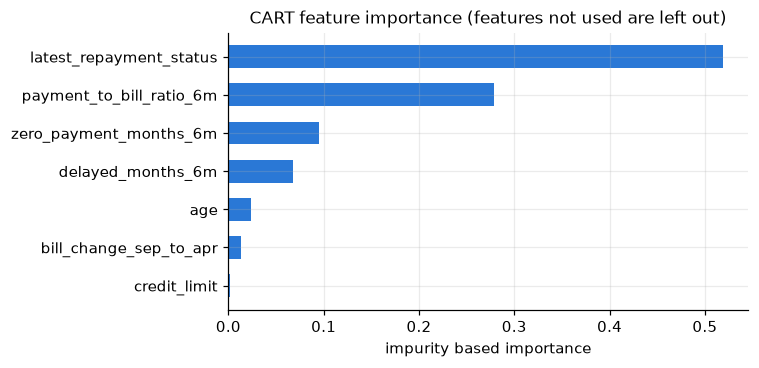

In [13]:
imp = pd.Series(cart.feature_importances_, index=X.columns).sort_values()
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1))
ax.barh(imp.index, imp.values, color=C_NEG, height=0.6)
ax.set_xlabel("impurity based importance")
ax.set_title("CART feature importance (features not used are left out)")
plt.tight_layout()
plt.show()

`latest_repayment_status` and `payment_to_bill_ratio_6m` take about 80% of the importance. Sex, education, marital status and the assistance plan are not used at all. As we saw in class, low importance doesn't mean a feature is useless, it can be masked by a correlated one. For example, `maximum_repayment_delay_6m` doesn't appear because `latest_repayment_status` and `delayed_months_6m` already carry that information.

### 3.2 Optimal sparse tree (GOSDT)

CART is greedy, so it may be spending leaves on splits that don't pay off. GOSDT instead searches for the tree that minimises misclassification plus `regularization` × number of leaves, over the binary features defined in section 2. Like in the class notebook, `predict` only gives hard labels, so we use the positive rate of each training leaf as its probability (needed for the AUC).

In [14]:
def gosdt_leaf(row, node):
    """Follow a row down a GOSDT tree, return (path as text, leaf prediction)."""
    conds = []
    while node.get("name") != "class":
        go_true = row[node["name"]] == node.get("reference", 1)
        conds.append(f"{node['name']} {'=' if go_true else '!='} {node.get('reference', 1)}")
        node = node["true"] if go_true else node["false"]
    return " and ".join(conds), int(node["prediction"])


class GOSDTClassifier:
    """Small wrapper so GOSDT behaves like a scikit-learn classifier inside our CV loop."""

    def __init__(self, regularization=0.001, depth_budget=3, time_limit=60):
        self.config = {"regularization": regularization, "depth_budget": depth_budget,
                       "time_limit": time_limit, "similar_support": False}

    def leaves(self, X):
        return X.apply(lambda r: gosdt_leaf(r, self.model_.tree.source)[0], axis=1)

    def fit(self, X, y):
        self.model_ = GOSDT(self.config)
        with contextlib.redirect_stdout(io.StringIO()):  # gosdt prints a lot
            self.model_.fit(X, y)
        leaf = self.leaves(X)
        self.leaf_summary_ = (pd.DataFrame({"leaf": leaf.values, "y": y.values}).groupby("leaf")["y"]
                              .agg(n="size", p_yes="mean").sort_values("p_yes"))
        self.prior_ = y.mean()
        return self

    def predict_proba(self, X):
        p = self.leaves(X).map(self.leaf_summary_["p_yes"]).fillna(self.prior_).to_numpy()
        return np.c_[1 - p, p]

    def predict(self, X):
        return self.model_.predict(X)

    def n_leaves(self):
        return self.model_.leaves()


gosdt_grid = []
for depth in [3, 4]:
    for reg in [0.005, 0.002, 0.001, 0.0005]:
        s, _ = cv_evaluate(lambda: GOSDTClassifier(regularization=reg, depth_budget=depth), X_bin, y)
        gosdt_grid.append({"depth_budget": depth, "regularization": reg, "leaves (mean over folds)": s.size_mean,
                           "accuracy": s.accuracy_mean, "acc_std": s.accuracy_std,
                           "roc_auc": s.roc_auc_mean, "fit_s": s.fit_s_mean})
gosdt_grid = pd.DataFrame(gosdt_grid)
gosdt_grid.round(4)

,depth_budget,regularization,leaves (mean over folds),accuracy,acc_std,roc_auc,fit_s
0,3,0.0050,2.0,0.8055,0.0028,0.5649,1.1197
1,3,0.0020,4.0,0.8132,0.0035,0.6199,1.1300
2,3,0.0010,4.0,0.8132,0.0035,0.6199,1.1410
3,3,0.0005,4.0,0.8132,0.0035,0.6199,1.2027
4,4,0.0050,2.0,0.8055,0.0028,0.5649,1.9837
5,4,0.0020,4.0,0.8132,0.0035,0.6610,2.2533
6,4,0.0010,4.0,0.8132,0.0035,0.6610,2.4003
7,4,0.0005,7.0,0.8154,0.0020,0.6494,2.5330


Two things stand out. First, with only **4 leaves** GOSDT already gets 0.813, the same as the 14 leaf CART. Second, with `depth_budget=4` and the smallest penalty we get **7 leaves and 0.8154**, the best accuracy of all the models, on par with CART at depth 7 (which has around 40 leaves). The result is also stable: 0.002 to 0.0005 give the same tree at depth 3.

The AUC is much lower than CART's, but that's expected. With 4 to 7 leaves the model only outputs 4 to 7 different scores and most clients fall in the same big leaf, so it can't rank them. Following our selection rule we keep the 7 leaf tree.

In [15]:
best_acc = gosdt_grid.accuracy.max()
chosen = gosdt_grid[gosdt_grid.accuracy >= best_acc - TOL].sort_values(["leaves (mean over folds)", "depth_budget"]).iloc[0]
GOSDT_PARAMS = {"regularization": float(chosen.regularization), "depth_budget": int(chosen.depth_budget)}
print("chosen:", GOSDT_PARAMS)
results["GOSDT"], oof_probs["GOSDT"] = cv_evaluate(lambda: GOSDTClassifier(**GOSDT_PARAMS), X_bin, y, "GOSDT")
gosdt = GOSDTClassifier(**GOSDT_PARAMS).fit(X_bin, y)
print(f"leaves: {gosdt.n_leaves()}\n")
print(gosdt.leaf_summary_.round(3).to_string())
show_cv(results["GOSDT"])

chosen: {'regularization': 0.0005, 'depth_budget': 4}


leaves: 7

                                                                                                      n  p_yes
leaf                                                                                                          
age_ge_25 = 1 and payment_to_bill_ratio_6m_ge_0.03 = 1 and delayed_months_6m_ge_6 != 1            20472  0.155
age_ge_25 != 1 and latest_repayment_status_ge_1 != 1                                               1625  0.243
age_ge_25 != 1 and latest_repayment_status_ge_1 = 1 and payment_to_bill_ratio_6m_ge_0.1 = 1         183  0.404
age_ge_25 = 1 and payment_to_bill_ratio_6m_ge_0.03 != 1 and maximum_repayment_delay_6m_ge_1 != 1    630  0.424
age_ge_25 = 1 and payment_to_bill_ratio_6m_ge_0.03 = 1 and delayed_months_6m_ge_6 = 1               847  0.638
age_ge_25 = 1 and payment_to_bill_ratio_6m_ge_0.03 != 1 and maximum_repayment_delay_6m_ge_1 = 1     804  0.680
age_ge_25 != 1 and latest_repayment_status_ge_1 = 1 and payment_to_bill_ratio_6m_ge_0.1 != 1        4

,accuracy,roc_auc,balanced_acc,f1,fit (s)
GOSDT,0.8154 ± 0.0020,0.6494 ± 0.0082,0.6132 ± 0.0030,0.3758 ± 0.0068,2.6


The tree is small enough to write in words. The first split is `age >= 25`, then:

* **25 or older** (91% of clients): if they pay at least 3% of their bills, predict "yes" only when they were late in all 6 months (64%); otherwise "no" (15.5%, this leaf alone has 82% of the data). If they pay less than 3%, predict "yes" as soon as they have been late at least once (68%).
* **Under 25**: predict "yes" only if they are currently late and paying less than 10% of their bills (69%).

So the model flags three profiles: late every month, paying almost nothing with some delay, and young, currently late and paying little. It is the same story as CART (being late + paying little) with half the leaves, and each branch can be explained in one sentence. Worth noting that 0.03 is our lowest payment ratio threshold and GOSDT picks it, so a finer threshold could help. Something to try in Phase II.

## 4. Model 2: rule list

A rule list is an ordered chain of `if / else if / ... / else`, and each instance is explained by the first rule that fires.

### 4.1 First try: greedy rule list

The cheapest option in `imodels` is `GreedyRuleListClassifier`, which builds the list greedily with depth 1 splits.

In [16]:
class GreedyRL(imodels.GreedyRuleListClassifier):
    def fit(self, X, y):
        return super().fit(X, y, feature_names=list(X.columns))


results["Greedy rule list"], _ = cv_evaluate(lambda: GreedyRL(max_depth=6), X, y, "Greedy rule list")
greedy = GreedyRL(max_depth=6).fit(X, y)
print(greedy)
show_cv(results["Greedy rule list"])

> ------------------------------
> Greedy Rule List
> ------------------------------
> if latest_repayment_status > 0.5 | 43.83% pred prob (5695 obs)
> else if payment_to_bill_ratio_6m <= 0.11 | 21.47% pred prob (9278 obs)
> else if payment_to_bill_ratio_6m > 1.74 | 18.78% pred prob (362 obs)
> else if age <= 24.5 | 14.33% pred prob (712 obs)
> else if repayment_assistance_plan_yes > 0.5 | 11.31% pred prob (1370 obs)
> else if zero_payment_months_6m > 2.5 | 10.31% pred prob (1193 obs)
> else | 5.74% pred prob (6390 obs)
> ------------------------------



,accuracy,roc_auc,balanced_acc,f1,fit (s)
Greedy rule list,0.7878 ± 0.0001,0.7186 ± 0.0059,0.5000 ± 0.0001,0.0000 ± 0.0000,0.1


This fails in an interesting way. Accuracy is exactly the baseline because **no rule reaches 50%**. The first rule (`latest_repayment_status > 0.5`) takes all currently late clients together at 44%. Since the algorithm removes those clients before learning the next rule, it can never go back and separate the really risky ones inside that group (the CART tree showed that late + paying little reaches 60 to 85%). Every rule predicts "no", so as a classifier it is useless, even if the AUC (0.72) shows the order makes some sense. The problem is the greedy construction, so we move on to a method that optimises the whole list.

### 4.2 Bayesian rule list (BRL)

BRL (Letham et al., 2015) first mines frequent conjunctions of our binary features and then samples lists with MCMC, with a prior that prefers short lists with short rules. It is slow (around 1.5 min per fit, so this cell takes about 9 minutes), so instead of a grid we use one reasonable setting: rules of at most 2 conditions, each covering at least 5% of the data, expected list length around 3, and 2 MCMC chains of 1000 iterations.

In [17]:
class BRL(imodels.BayesianRuleListClassifier):
    def fit(self, X, y):
        return super().fit(X, y, feature_names=list(X.columns))


BRL_PARAMS = {"listlengthprior": 3, "maxcardinality": 2, "minsupport": 0.05, "max_iter": 1000,
              "n_chains": 2, "random_state": SEED}
results["BRL"], oof_probs["BRL"] = cv_evaluate(lambda: BRL(**BRL_PARAMS), X_bin, y, "BRL")
brl = BRL(**BRL_PARAMS).fit(X_bin, y)
print(brl)
show_cv(results["BRL"])

Trained RuleListClassifier 
IF delayed_months_6m_ge_1 > 0.5 and payment_to_bill_ratio_6m_ge_0.1 > 0.5 THEN probability of class 1: 18.4% (17.0%-19.7%)
ELSE IF latest_repayment_status_ge_1 > 0.5 and payment_to_bill_ratio_6m_ge_0.03 > 0.5 THEN probability of class 1: 49.0% (47.2%-50.8%)
ELSE IF latest_repayment_status_ge_2 > 0.5 and maximum_repayment_delay_6m_ge_2 > 0.5 THEN probability of class 1: 87.2% (83.0%-90.9%)
ELSE IF latest_repayment_status_ge_1 > 0.5 and maximum_repayment_delay_6m_ge_1 > 0.5 THEN probability of class 1: 61.7% (57.7%-65.6%)
ELSE IF assistance_plan > 0.5 and utilization_sep_ge_0.9 > 0.5 THEN probability of class 1: 32.5% (29.2%-35.8%)
ELSE IF assistance_plan > 0.5 and payment_to_bill_ratio_6m_ge_0.1 > 0.5 THEN probability of class 1: 11.7% (10.0%-13.5%)
ELSE IF payment_to_bill_ratio_6m_ge_0.1 > 0.5 and zero_payment_months_6m_ge_3 > 0.5 THEN probability of class 1: 11.8% (10.0%-13.8%)
ELSE IF assistance_plan > 0.5 and utilization_sep_ge_0.5 > 0.5 THEN probability 

,accuracy,roc_auc,balanced_acc,f1,fit (s)
BRL,0.8053 ± 0.0055,0.7442 ± 0.0069,0.6200 ± 0.0071,0.3937 ± 0.0155,59.8


BRL does learn positive rules: 0.805 accuracy and 0.744 AUC, the best ranking after CART. But it needs 13 rules, and the list is harder to read than it looks because **rules only make sense in order**. The first rule (delayed at least once but paying 10% or more) removes a low risk group (18%), and only then do the next rules find the risky clients (currently 2+ months late with a max delay of 2+: 87%). The meaning of rule 5 depends on rules 1 to 4 being false, and after 5 or 6 rules it's hard to say what population is left. The final `else` (42.7%) is what remains: clients paying less than 3% who didn't match anything above.

In our tests the list also changed quite a lot with small changes in the training data, and its accuracy std across folds is the largest of all the models. That's typical of MCMC with few iterations.

## 5. Model 3: rule set (RIPPER)

A rule set is an unordered collection of rules for the positive class: predict "yes" if **any** rule fires, "no" otherwise. We use RIPPER from `wittgenstein`, which grows and prunes rules one at a time and discretises numeric features internally into quantile bins. Left alone it learns more than 30 rules, so we cap the number of rules and conditions per rule and tune both with CV.

In [18]:
class RipperClassifier:
    def __init__(self, **kw):
        self.kw = kw

    def fit(self, X, y):
        self.model_ = lw.RIPPER(random_state=SEED, **self.kw)
        self.model_.fit(X, y, pos_class=1)
        return self

    def predict(self, X):
        return np.asarray(self.model_.predict(X)).astype(int)

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def n_leaves(self):
        return len(self.model_.ruleset_.rules)


ripper_grid = []
for max_rules in [3, 5, 8, 12]:
    for max_conds in [2, 3]:
        s, _ = cv_evaluate(lambda: RipperClassifier(max_rules=max_rules, max_rule_conds=max_conds), X, y)
        ripper_grid.append({"max_rules": max_rules, "max_rule_conds": max_conds, "accuracy": s.accuracy_mean,
                            "acc_std": s.accuracy_std, "roc_auc": s.roc_auc_mean, "f1": s.f1_mean, "rules": s.size_mean, "fit_s": s.fit_s_mean})
ripper_grid = pd.DataFrame(ripper_grid)
ripper_grid.round(4)

,max_rules,max_rule_conds,accuracy,acc_std,roc_auc,f1,rules,fit_s
0,3,2,0.7902,0.0075,0.6191,0.3872,3.0,1.6222
1,3,3,0.7995,0.0032,0.5466,0.1846,3.0,1.6830
2,5,2,0.7926,0.0094,0.6338,0.4153,4.8,1.9561
3,5,3,0.8009,0.0040,0.5599,0.2303,5.0,2.0301
4,8,2,0.7881,0.0105,0.6515,0.4427,7.4,2.4384
5,8,3,0.8043,0.0036,0.5882,0.3109,8.0,2.6402
6,12,2,0.7836,0.0139,0.6626,0.4580,9.4,3.5059
7,12,3,0.8062,0.0047,0.6073,0.3601,12.0,3.4152


Two trends. Rules with 3 conditions give better accuracy but worse AUC and F1 than rules with 2. With 2 conditions the rules are more general, so they fire more often and catch more positives (higher F1), but they also bring more false positives, which hurts accuracy with this imbalance. More rules improve accuracy slowly. With our selection rule we keep `max_rules=8, max_rule_conds=3` (0.8043, within 0.002 of the 12 rule set).

The AUC of RIPPER is low by construction: its probabilities are basically two values (some rule fires or none does), so it can't rank clients.

In [19]:
best_acc = ripper_grid.accuracy.max()
chosen = ripper_grid[ripper_grid.accuracy >= best_acc - TOL].sort_values(["rules", "max_rule_conds"]).iloc[0]
RIPPER_PARAMS = {"max_rules": int(chosen.max_rules), "max_rule_conds": int(chosen.max_rule_conds)}
print("chosen:", RIPPER_PARAMS)
results["RIPPER"], oof_probs["RIPPER"] = cv_evaluate(lambda: RipperClassifier(**RIPPER_PARAMS), X, y, "RIPPER")
ripper = RipperClassifier(**RIPPER_PARAMS).fit(X, y)
ripper.model_.out_model()

# coverage and precision of each rule on the training data (rules work on RIPPER's own bins,
# so we ask the model which rules fire for each row instead of evaluating them by hand)
_, reasons = ripper.model_.predict(X, give_reasons=True)
fired = pd.Series([[str(r) for r in rr] for rr in reasons], index=X.index)
cov = pd.DataFrame([{"rule": str(r), "covers": int(fired.apply(lambda f: str(r) in f).sum()),
                     "p_yes": y[fired.apply(lambda f: str(r) in f)].mean()} for r in ripper.model_.ruleset_.rules])
print(f"default rule (no rule fires): {int((fired.str.len() == 0).sum())} rows, p_yes = {y[fired.str.len() == 0].mean():.3f}")
with pd.option_context("display.max_colwidth", 120):
    display(cov.round(3))
show_cv(results["RIPPER"])

chosen: {'max_rules': 8, 'max_rule_conds': 3}


[[payment_to_bill_ratio_6m=<0.03 ^ total_payment_6m=<2400.0 ^ delayed_months_6m=6] V
[payment_to_bill_ratio_6m=<0.03 ^ total_payment_6m=<2400.0 ^ latest_repayment_status=0.0-1.0] V
[latest_repayment_status=1.0-2.0 ^ delayed_months_6m=6 ^ repayment_assistance_plan_no=0] V
[latest_repayment_status=1.0-2.0 ^ delayed_months_6m=6] V
[payment_to_bill_ratio_6m=<0.03 ^ total_payment_6m=<2400.0 ^ latest_repayment_status=>2.0] V
[payment_to_bill_ratio_6m=<0.03 ^ latest_repayment_status=1.0-2.0 ^ zero_payment_months_6m=6] V
[payment_to_bill_ratio_6m=<0.03 ^ repayment_assistance_plan_no=0 ^ utilization_sep=>0.98] V
[payment_to_bill_ratio_6m=<0.03 ^ total_payment_6m=<2400.0 ^ marital_status_married=0]]


default rule (no rule fires): 23201 rows, p_yes = 0.180


,rule,covers,p_yes
0,[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^delayed_months_6m=6],142,0.930
1,[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^latest_repayment_status=0.0-1.0],530,0.615
2,[latest_repayment_status=1.0-2.0^delayed_months_6m=6^repayment_assistance_plan_no=0],237,0.755
3,[latest_repayment_status=1.0-2.0^delayed_months_6m=6],587,0.687
4,[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^latest_repayment_status=>2.0],105,0.962
5,[payment_to_bill_ratio_6m=<0.03^latest_repayment_status=1.0-2.0^zero_payment_months_6m=6],83,0.867
6,[payment_to_bill_ratio_6m=<0.03^repayment_assistance_plan_no=0^utilization_sep=>0.98],244,0.590
7,[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^marital_status_married=0],695,0.584


,accuracy,roc_auc,balanced_acc,f1,fit (s)
RIPPER,0.8043 ± 0.0036,0.5882 ± 0.0186,0.5874 ± 0.0183,0.3109 ± 0.0513,2.6


RIPPER's own discretisation gives the rules a different flavour. The lowest bins `payment_to_bill_ratio_6m=<0.03` and `total_payment_6m=<2400` appear in 6 of the 8 rules, so the rule set basically says: **the client pays almost nothing AND something else is wrong** (delayed all 6 months, currently late, card maxed out...).

The rules are very precise (58% to 96%), but together they cover only about 1800 clients (7%). The other 23201 get the default "no" with an 18% difficulty rate, so many positives are never caught (F1 0.31). There is also redundancy: rule 3 is a special case of rule 4 (same conditions plus `repayment_assistance_plan_no=0`), so it could be deleted without changing any prediction. Some conditions, like `marital_status_married=0`, look more like overfitting to the bins than real signal.

## 6. Comparison

In [20]:
size = {"Majority baseline": 1, "CART": cart.get_n_leaves(), "GOSDT": gosdt.n_leaves(),
        "Greedy rule list": len(greedy.rules_) + 1, "BRL": len(brl.final_itemsets), "RIPPER": len(ripper.model_.ruleset_.rules) + 1}
settings = {"Majority baseline": "most_frequent",
            "CART": f"max_depth={TREE_PARAMS['max_depth']}, min_samples_leaf={TREE_PARAMS['min_samples_leaf']}",
            "GOSDT": f"regularization={GOSDT_PARAMS['regularization']}, depth_budget={GOSDT_PARAMS['depth_budget']}",
            "Greedy rule list": "max_depth=6",
            "BRL": "maxcardinality=2, minsupport=0.05, listlengthprior=3",
            "RIPPER": f"max_rules={RIPPER_PARAMS['max_rules']}, max_rule_conds={RIPPER_PARAMS['max_rule_conds']}"}
summary = pd.concat([show_cv(results[k]) for k in results])
summary.insert(0, "leaves / rules (incl. default)", [size[k] for k in results])
summary.insert(0, "key settings", [settings[k] for k in results])
summary

,key settings,leaves / rules (incl. default),accuracy,roc_auc,balanced_acc,f1,fit (s)
Majority baseline,most_frequent,1,0.7879 ± 0.0001,0.5000 ± 0.0000,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0
CART,"max_depth=4, min_samples_leaf=200",14,0.8133 ± 0.0023,0.7465 ± 0.0051,0.6024 ± 0.0045,0.3491 ± 0.0107,0.1
GOSDT,"regularization=0.0005, depth_budget=4",7,0.8154 ± 0.0020,0.6494 ± 0.0082,0.6132 ± 0.0030,0.3758 ± 0.0068,2.6
Greedy rule list,max_depth=6,8,0.7878 ± 0.0001,0.7186 ± 0.0059,0.5000 ± 0.0001,0.0000 ± 0.0000,0.1
BRL,"maxcardinality=2, minsupport=0.05, listlengthp...",13,0.8053 ± 0.0055,0.7442 ± 0.0069,0.6200 ± 0.0071,0.3937 ± 0.0155,59.8
RIPPER,"max_rules=8, max_rule_conds=3",9,0.8043 ± 0.0036,0.5882 ± 0.0186,0.5874 ± 0.0183,0.3109 ± 0.0513,2.6


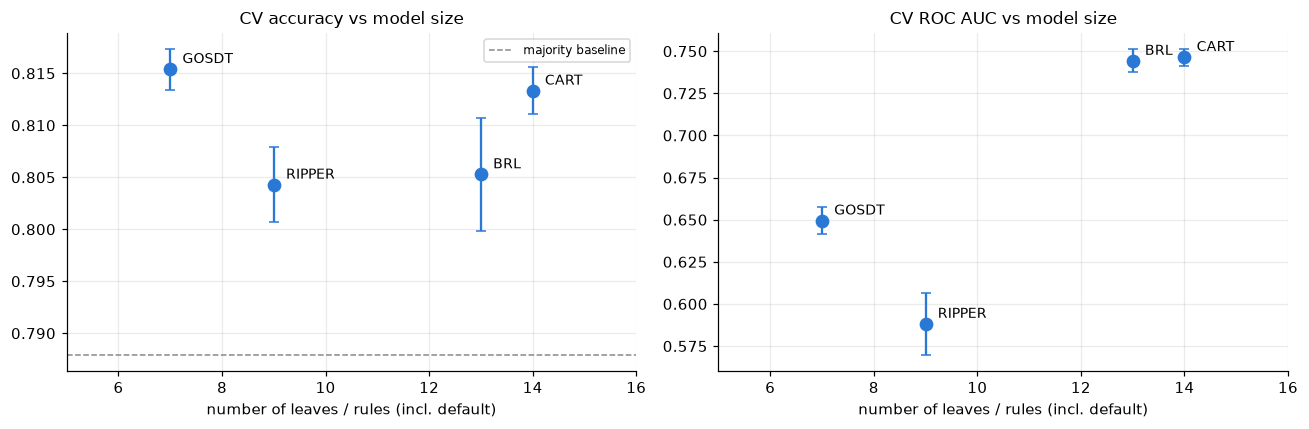

In [21]:
models = ["CART", "GOSDT", "BRL", "RIPPER"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, m, title in zip(axes, ["accuracy", "roc_auc"], ["CV accuracy", "CV ROC AUC"]):
    xs = [size[k] for k in models]
    ys = [results[k][f"{m}_mean"] for k in models]
    es = [results[k][f"{m}_std"] for k in models]
    ax.errorbar(xs, ys, yerr=es, fmt="o", ms=8, color=C_NEG, capsize=3)
    for x_, y_, k in zip(xs, ys, models):
        ax.annotate(k, (x_, y_), textcoords="offset points", xytext=(8, 4), fontsize=9)
    ax.set_xlim(5, 16)
    ax.set_xlabel("number of leaves / rules (incl. default)")
    ax.set_title(title + " vs model size")
axes[0].axhline(1 - y.mean(), color=C_REF, ls="--", lw=1, label="majority baseline")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

All logical models (except the greedy list) beat the baseline, but by a modest margin (+1.6 to +2.8 points). That matches the EDA: the signal is concentrated in a handful of behavioural variables.

* **GOSDT** has the best accuracy (0.8154) with the smallest model (7 leaves), and it's stable across folds.
* **CART** is almost as accurate with twice the leaves, and gives the best AUC, so it's the best at ranking clients.
* **BRL** sits in the middle on accuracy with a good AUC, but its 13 ordered rules are the hardest to read.
* **RIPPER** has very precise rules but misses most positives, so it's the weakest.

The accuracy gap between GOSDT and CART is within one standard deviation, so we can't claim GOSDT predicts better. What it clearly wins on is simplicity.

### Classification threshold

All the numbers above use each model's default decision rule. Since the grade uses accuracy on `test.csv`, we check with the out of fold probabilities whether another threshold would help.

CART    best threshold 0.49 -> OOF accuracy 0.8133


GOSDT   best threshold 0.44 -> OOF accuracy 0.8154


BRL     best threshold 0.52 -> OOF accuracy 0.8054


RIPPER  best threshold 0.58 -> OOF accuracy 0.8043


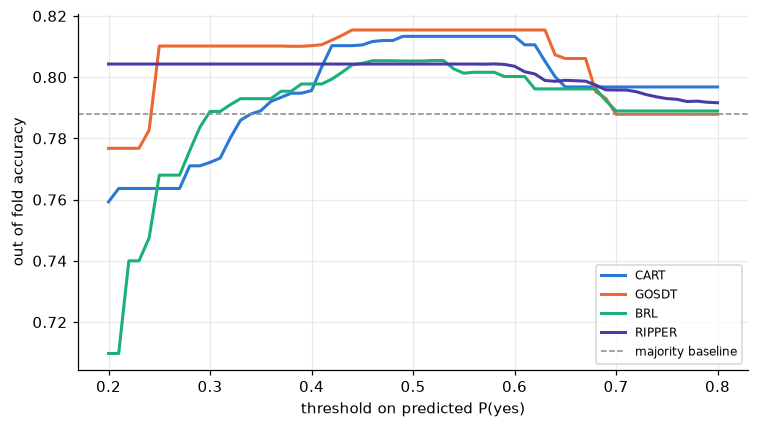

In [22]:
ths = np.linspace(0.2, 0.8, 61)
fig, ax = plt.subplots(figsize=(7, 4))
for k, col in zip(models, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]):
    accs = [accuracy_score(y, oof_probs[k] >= t) for t in ths]
    ax.plot(ths, accs, lw=2, color=col, label=k)
    print(f"{k:7s} best threshold {ths[int(np.argmax(accs))]:.2f} -> OOF accuracy {max(accs):.4f}")
ax.axhline(1 - y.mean(), color=C_REF, ls="--", lw=1, label="majority baseline")
ax.set_xlabel("threshold on predicted P(yes)")
ax.set_ylabel("out of fold accuracy")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

No threshold beats the default decision in a meaningful way. The best thresholds are all around 0.5, or 0.5 falls inside their plateau, which makes sense because 0.5 is the optimal threshold for accuracy when the leaf rates are calibrated. For GOSDT the curve is flat between roughly 0.43 and 0.63 because no leaf has a rate in that range. So we keep the default decisions. If the goal were catching positives (recall), a lower threshold would be the way to go, but that's not the metric of this task.

## 7. Local explanations (preview)

For Phase II we need the same instances explained by the three model families, so we fix them now. We take three clients at random (with the seed): a clear risky profile (difficulty, currently late and delayed all six months), a client with difficulty but a clean history, and a client without difficulty.

In [23]:
rng = np.random.RandomState(SEED)
LOCAL_IDX = [rng.choice(np.where((y == 1) & (train.latest_repayment_status >= 1) & (train.delayed_months_6m == 6))[0]),
             rng.choice(np.where((y == 1) & (train.delayed_months_6m == 0))[0]),
             rng.choice(np.where(y == 0)[0])]
display(train.iloc[LOCAL_IDX].T)


def cart_path(model, x):
    t, node, conds = model.tree_, 0, []
    while t.feature[node] != _tree.TREE_UNDEFINED:
        f, thr = X.columns[t.feature[node]], t.threshold[node]
        if x[f] <= thr:
            conds.append(f"{f} <= {thr:.2f}")
            node = t.children_left[node]
        else:
            conds.append(f"{f} > {thr:.2f}")
            node = t.children_right[node]
    v = t.value[node][0]
    return " and ".join(conds), v[1] / v.sum()


def first_brl_rule(model, xb):
    """BRL items are 'feature = 1' conditions; return the first rule of the list that fires."""
    for i, itemset in enumerate(model.final_itemsets[:-1]):
        cols = [model.feature_dict_[it] for it in itemset]
        if all(xb[c] == 1 for c in cols):
            return f"rule {i + 1}: " + " and ".join(cols)
    return "default (else) rule"


for i in LOCAL_IDX:
    x, xb = X.iloc[i], X_bin.iloc[i]
    path, p = cart_path(cart, x)
    fired_i = fired.iloc[i]
    print(f"=== {train.row_id[i]} | true class: {y.iloc[i]} ===")
    print(f"CART   -> P(yes)={p:.2f} | {path}")
    print(f"GOSDT  -> pred={gosdt.predict(X_bin.iloc[[i]])[0]} | {gosdt_leaf(xb, gosdt.model_.tree.source)[0]}")
    print(f"BRL    -> P(yes)={brl.predict_proba(X_bin.iloc[[i]])[0, 1]:.2f} | {first_brl_rule(brl, xb)}")
    print(f"RIPPER -> pred={ripper.predict(X.iloc[[i]])[0]} | {fired_i if fired_i else 'no rule fires, default no'}\n")

,3282,9144,6795
row_id,CR26-102000,CR26-129090,CR26-126238
credit_limit,10000,180000,10000
sex,female,male,male
education,graduate_school,graduate_school,university
marital_status,single,single,married
age,23,31,50
latest_repayment_status,3,-1,0
maximum_repayment_delay_6m,7,0,0
delayed_months_6m,6,0,0
average_bill_6m,2400,900,5900


=== CR26-102000 | true class: 1 ===
CART   -> P(yes)=0.85 | latest_repayment_status > 0.50 and payment_to_bill_ratio_6m <= 0.11 and delayed_months_6m > 5.50 and bill_change_sep_to_apr > -850.00
GOSDT  -> pred=1 | age_ge_25 != 1 and latest_repayment_status_ge_1 = 1 and payment_to_bill_ratio_6m_ge_0.1 != 1
BRL    -> P(yes)=0.87 | rule 3: latest_repayment_status_ge_2 and maximum_repayment_delay_6m_ge_2
RIPPER -> pred=1 | ['[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^delayed_months_6m=6]', '[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^latest_repayment_status=>2.0]', '[payment_to_bill_ratio_6m=<0.03^total_payment_6m=<2400.0^marital_status_married=0]']

=== CR26-129090 | true class: 1 ===
CART   -> P(yes)=0.07 | latest_repayment_status <= 0.50 and payment_to_bill_ratio_6m > 0.11 and payment_to_bill_ratio_6m <= 1.74 and age > 24.50
GOSDT  -> pred=0 | age_ge_25 = 1 and payment_to_bill_ratio_6m_ge_0.03 = 1 and delayed_months_6m_ge_6 != 1


BRL    -> P(yes)=0.06 | rule 11: payment_to_bill_ratio_6m_ge_0.1
RIPPER -> pred=0 | no rule fires, default no

=== CR26-126238 | true class: 0 ===
CART   -> P(yes)=0.07 | latest_repayment_status <= 0.50 and payment_to_bill_ratio_6m > 0.11 and payment_to_bill_ratio_6m <= 1.74 and age > 24.50
GOSDT  -> pred=0 | age_ge_25 = 1 and payment_to_bill_ratio_6m_ge_0.03 = 1 and delayed_months_6m_ge_6 != 1


BRL    -> P(yes)=0.06 | rule 11: payment_to_bill_ratio_6m_ge_0.1
RIPPER -> pred=0 | no rule fires, default no



* **CR26-102000 (difficulty, clear case).** All four models say "yes", but each gives a different reason. CART: currently late, paying under 11% and delayed all 6 months (85%). GOSDT: under 25, currently late and paying under 10%, so it goes down the age branch. BRL: rule 3, currently 2+ months late (87%). RIPPER: three rules fire at once, one of them being the dubious `marital_status_married=0` rule. Same decision, several explanations: with redundant features like the delay variables this is expected, and it's a good example for the "conflicting explanations" part of Phase II.
* **CR26-129090 (difficulty, clean history)** and **CR26-126238 (no difficulty).** Every model says "no" for both, and they land in exactly the same leaf or rule in all four models (P(yes) around 0.06 to 0.07). The first one pays 100% of the bill and has never been late, so from the model's point of view it is indistinguishable from the good client. This kind of positive is out of reach for these features, which is where most of the missed positives (low recall) come from.

## 8. Preliminary conclusions

* The problem is hard to predict. The best logical models reach about 0.815 accuracy against 0.788 for the majority baseline, and almost all of the signal comes from repayment behaviour: being late right now, the number of delayed months and paying very little of the bill. Demographics, including sex, are barely used.
* All the learners tell a consistent story (difficulty = late + paying little). They mostly differ in where they cut the thresholds and in how readable the result is.
* As the logical model for the final project we propose the **GOSDT tree** (7 leaves, CV accuracy 0.8154 ± 0.0020): the most accurate and by far the easiest to explain. CART (depth 4) stays as a reference because it ranks clients better (AUC 0.75 vs 0.65), which may matter when we compare with the other families. The greedy rule list is discarded (it never predicts positive), and BRL and RIPPER are beaten by the trees in both accuracy and readability.

**Next steps for Phase II:** logistic regression and EBM with the same CV split, local explanations of the same three clients across the three families, a descriptive audit of the errors by sex, finer thresholds for the binary features (especially payment ratio below 0.03), and pruning the CART splits that don't change the prediction.